# WP12 · Gerçek iki kullanıcı PDF'siyle kaynak doğrulama pilotu

Kaynaklar kullanıcı tarafından tam dosya adı/yoluyla seçildi. Bu notebook gerçek PDF metinlerini gösterir;örnek/sahte prospektüs içermez. Bütün fiziksel sayfalar PyMuPDF ile çıkarıldı;OCR veyaOllama/LLM/model eğitimi yoktur. **Kaynak alıntısı model etiketi/tahmini değildir.**

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

import html
from IPython.display import HTML,Image
Q=ROOT/'reports/qa/WP12/pilot_v1';F=ROOT/'reports/figures/WP12/pilot_v1'
bundle=json.loads((Q/'source_evidence_bundle.json').read_text(encoding='utf-8'))
annotations=json.loads((Q/'source_context_annotations.json').read_text(encoding='utf-8'))
from wp12_document_contract import validate_bundle
display(pd.DataFrame([validate_bundle(bundle)]));display(pd.read_csv(Q/'document_inventory.csv'))
display(pd.read_csv(Q/'pdfinfo_page_count_crosscheck.csv'))


,documents,extraction_runs,pages,quotes,data_status
0,2,2,17,44,user_pdf_records


,filename,bytes,pages,raw_SHA256,content_revision,type
0,pil.502.pdf,136759,6,1b8182521f1314c595451e14a881caa930ba8a5df3c99d468e50429d0e61533e,December 2025,patient_information_leaflet
1,050641Orig1s032lbl.pdf,550960,11,237080fbda2eb353f322921302401bcc98d6a8e54dece1f8e9d11c886dfddcd5,02/2022,prescribing_information_label_with_package_image_and_signature


,filename,PyMuPDF_pages,Poppler_pdfinfo_pages,status
0,pil.502.pdf,6,6,PASS
1,050641Orig1s032lbl.pdf,11,11,PASS


**Yorum:**2 gerçek belge/17 fiziksel sayfa vardır. HamSHA dosya kimliğidir;dosyanın yayımlayıcısını veya klinik doğruluğunu kanıtlamaz. Kullanıcı provenansı mevcut açık seçim talimatına bağlanır;internetten alternatif dosya alınmadı.

## 1. Fiziksel sayfalar veçıkarım kapsamı

,filename,document_id,page_id,physical_page_number,chars,text_sha256,width_points,height_points,image_objects,image_area_sum_over_page_not_union,blank_text,replacement_char_count,text_file,text_coverage_status,image_content_not_transcribed,visual_review
0,pil.502.pdf,sha256:1b8182521f1314c595451e14a881caa930ba8a5df3c99d468e50429d0e61533e,page:b2c73839cbf7d8f600d1d58e5bbd35e0b76fd86e06caa193dc611547bc7bb10d,1,2352,96a7e6cc6f502154d371c727e9c0707ee0534e1d82a0945a08856553f1767237,595.380005,841.919983,0,0.000000,False,0,reports/qa/WP12/pilot_v1/page_text/pil.502.pdf.page_001.txt,TEXT_LAYER_PRESENT,False,all-page contact sheet;priority pages full-size
1,pil.502.pdf,sha256:1b8182521f1314c595451e14a881caa930ba8a5df3c99d468e50429d0e61533e,page:974e88ddc1d84b135db94f42f236b10993c5d9bf7b49df81b52977a6d78584a3,2,3163,1d821fa15c4f600ab001faeed16424398917f72af3a7a1ebde68072a4ffb3097,595.380005,841.919983,0,0.000000,False,0,reports/qa/WP12/pilot_v1/page_text/pil.502.pdf.page_002.txt,TEXT_LAYER_PRESENT,False,all-page contact sheet;priority pages full-size
2,pil.502.pdf,sha256:1b8182521f1314c595451e14a881caa930ba8a5df3c99d468e50429d0e61533e,page:5b0ecdba9c96440529efcf859d56a8ce628891d19f845fefa9346e758d7dba70,3,3148,cbd470399ea09fbd69e90e4a716b63416b58d9bfe9d2c7c1750c732e2e96cdf2,595.380005,841.919983,0,0.000000,False,0,reports/qa/WP12/pilot_v1/page_text/pil.502.pdf.page_003.txt,TEXT_LAYER_PRESENT,False,all-page contact sheet;priority pages full-size
3,pil.502.pdf,sha256:1b8182521f1314c595451e14a881caa930ba8a5df3c99d468e50429d0e61533e,page:8b8008aa00c6cdae92d59d529b3e8a4689e557b39bddef475b6043b2c32a6355,4,2087,39fbb1d7b62792ebca1fe15d5f074bd074accfcc8a04081352931c805c23496e,595.380005,841.919983,0,0.000000,False,0,reports/qa/WP12/pilot_v1/page_text/pil.502.pdf.page_004.txt,TEXT_LAYER_PRESENT,False,all-page contact sheet;priority pages full-size
4,pil.502.pdf,sha256:1b8182521f1314c595451e14a881caa930ba8a5df3c99d468e50429d0e61533e,page:e6a9d9879cea31d2eb833f9681ad14f2b65dcd524a1e5b6049dd7a7d32d46612,5,2529,7fd1aa62663df4c1eca7995bb9cc58c7d06484d91d5355652dc0406cf3166ed9,595.380005,841.919983,0,0.000000,False,0,reports/qa/WP12/pilot_v1/page_text/pil.502.pdf.page_005.txt,TEXT_LAYER_PRESENT,False,all-page contact sheet;priority pages full-size
5,pil.502.pdf,sha256:1b8182521f1314c595451e14a881caa930ba8a5df3c99d468e50429d0e61533e,page:ff48b3acb4ed655c35c301acc2154fd60d523b0d4b9d48091b6749f34d3ad2f6,6,1860,e9bd9ca8488868bdc838f302baa683ad18068194f7957c827c42116c5f28e834,595.380005,841.919983,0,0.000000,False,0,reports/qa/WP12/pilot_v1/page_text/pil.502.pdf.page_006.txt,TEXT_LAYER_PRESENT,False,all-page contact sheet;priority pages full-size
6,050641Orig1s032lbl.pdf,sha256:237080fbda2eb353f322921302401bcc98d6a8e54dece1f8e9d11c886dfddcd5,page:76a430523d3cf30c9370b41dd4fd58298eabc96f19f410892ade9fff686fdce6,1,2926,7acb33da210618def552f9a784de91b75ffaf8ccd683544ebabb011a06f95cc1,612.000000,792.000000,1,0.076725,False,0,reports/qa/WP12/pilot_v1/page_text/050641Orig1s032lbl.pdf.page_001.txt,TEXT_LAYER_PRESENT,True,all-page contact sheet;priority pages full-size
7,050641Orig1s032lbl.pdf,sha256:237080fbda2eb353f322921302401bcc98d6a8e54dece1f8e9d11c886dfddcd5,page:4d6666a37c63c886e882be2c1d5c88326c12ca61e7f81016ad926f64d529f61e,2,1557,0e923f3b3d5eaaf130101420c75ed48d6e658e74b4d710696e1d0bea5ab55c68,612.000000,792.000000,0,0.000000,False,0,reports/qa/WP12/pilot_v1/page_text/050641Orig1s032lbl.pdf.page_002.txt,TEXT_LAYER_PRESENT,False,all-page contact sheet;priority pages full-size
8,050641Orig1s032lbl.pdf,sha256:237080fbda2eb353f322921302401bcc98d6a8e54dece1f8e9d11c886dfddcd5,page:94f2feaad2aab56f0e26cfe041b935556932bbe96037952b3e055ab94c8284f1,3,3719,e674cee81776de40fc23cf65c556b06e15b130f732e273eb04752ebbfc4976da,612.000000,792.000000,0,0.000000,False,0,reports/qa/WP12/pilot_v1/page_text/050641Orig1s032lbl.pdf.page_003.txt,TEXT_LAYER_PRESENT,False,all-page contact sheet;priority pages full-size
9,050641Orig1s032lbl.pdf,sha256:237080fbda2eb353f322921302401bc

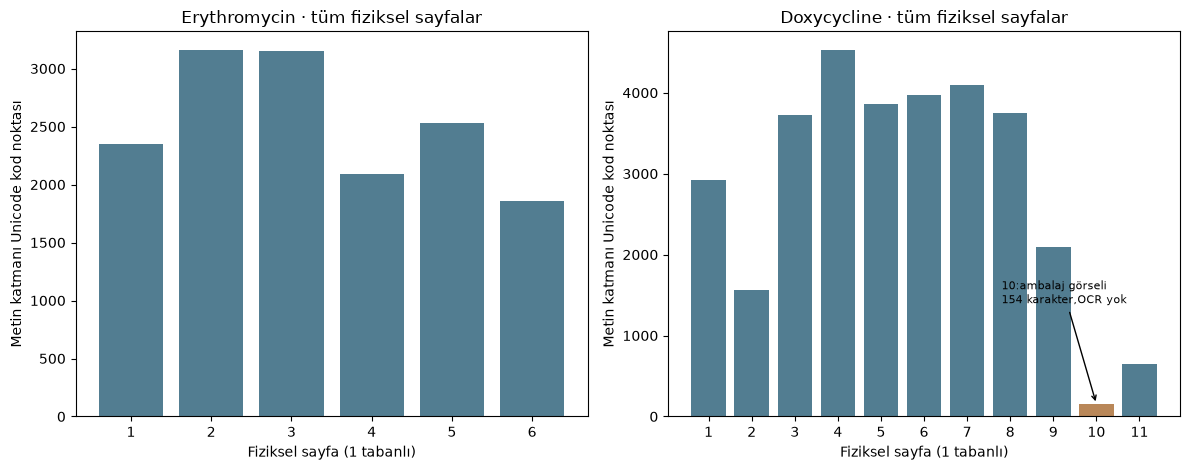

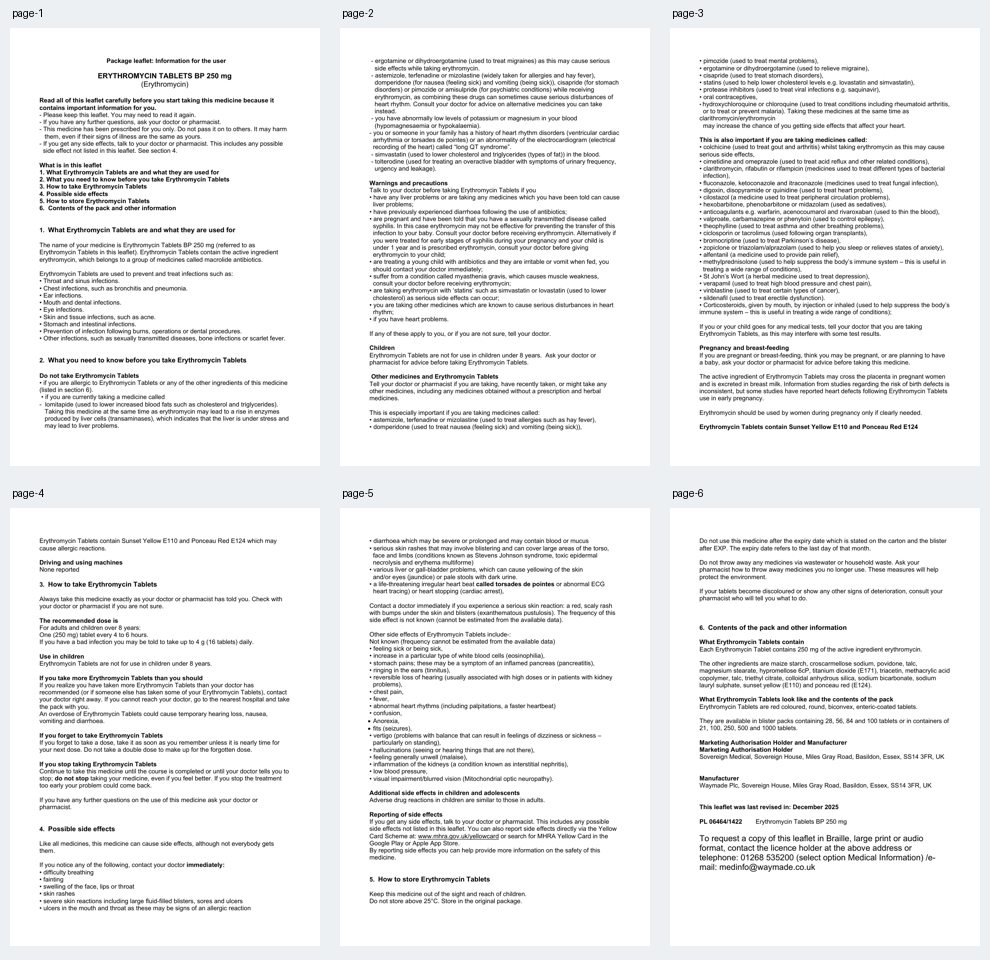

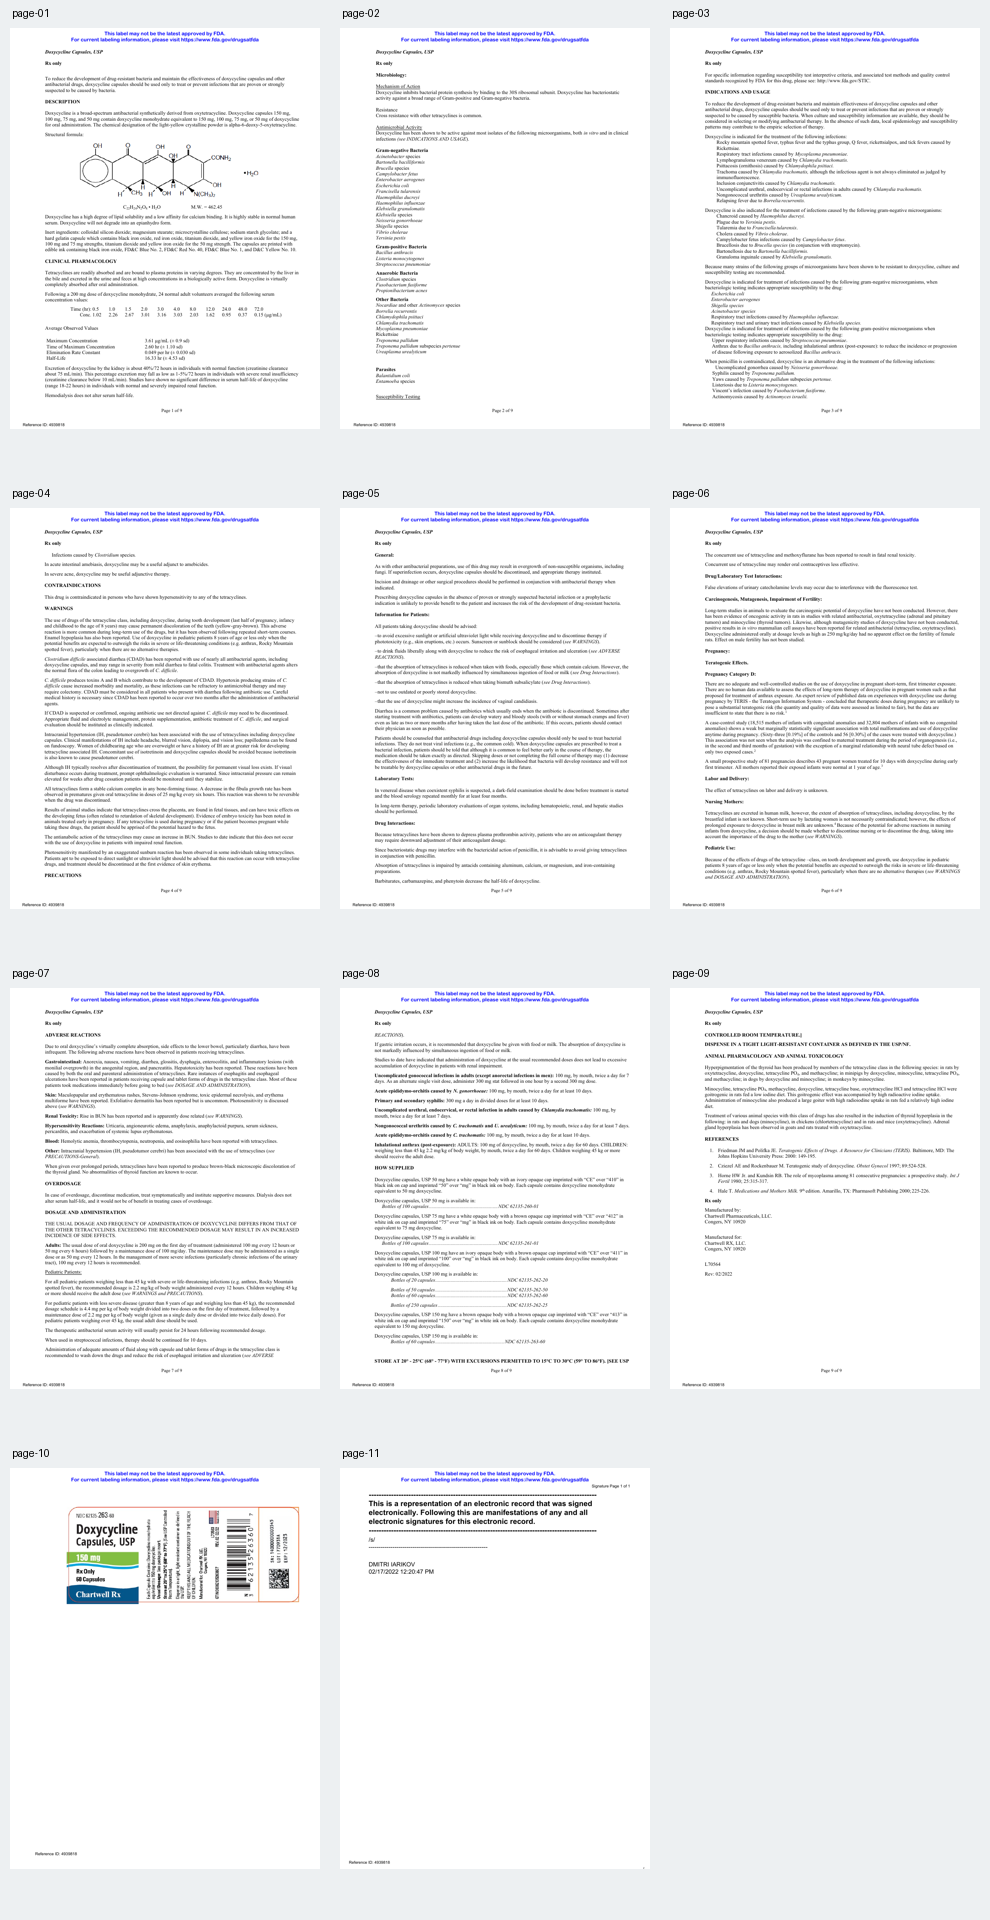

In [2]:

pages=pd.read_csv(Q/'page_text_coverage_review.csv');display(pages)
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
for ax,name,label in zip(axs,['pil.502.pdf','050641Orig1s032lbl.pdf'],['Erythromycin','Doxycycline']):
    d=pages[pages.filename.eq(name)];ax.bar(d.physical_page_number,d.chars,color=['#b98758' if s=='SPARSE_TEXT_SUBSTANTIVE_IMAGE_NO_OCR' else '#527d91' for s in d.text_coverage_status])
    ax.set(title=label+' · tüm fiziksel sayfalar',xlabel='Fiziksel sayfa (1 tabanlı)',ylabel='Metin katmanı Unicode kod noktası',xticks=d.physical_page_number)
axs[1].annotate('10:ambalaj görseli\n154 karakter,OCR yok',xy=(10,154),xytext=(7.8,1400),arrowprops={'arrowstyle':'->'},fontsize=8)
plt.tight_layout();plt.savefig(F/'01_physical_page_text_coverage.png',dpi=160);plt.show()
display(Image(filename=str(F/'erythromycin_all_pages_contact.png')))
display(Image(filename=str(F/'doxycycline_all_pages_contact.png')))


**Grafik yorumu:**Boş metin sayfası0 olması,görsel içeriğin tamamen metne dönüştürüldüğü anlamına gelmez. Doxycycline fiziksel10'da yalnızfooter metni çıkar;ambalaj görseli saklanır veOCR yapılmaz. Fiziksel11 imza temsilidir. Ana metindeki “Page7 of9”,17 toplam sayfanın sayılmasıyla karıştırılmaz;belge kendi içinde11 fiziksel sayfadır.

## 2. Belge türü,sürüm veana ilaç/formülasyon

In [3]:

display(pd.DataFrame(json.loads((Q/'document_metadata_content_review.json').read_text(encoding='utf-8'))))
identity=json.loads((Q/'drug_identity_review.json').read_text(encoding='utf-8'));display(pd.DataFrame(identity)[['filename','DrugBank_parent_id','existing_parent_name','existing_CID','PDF_formulation','PDF_named_salt_or_hydrate','existing_salt_link_id','mapping_level','product_or_dose_equivalence']])
display(pd.read_csv(Q/'existing_parent_salt_links_review.csv'))


,filename,document_id,document_type_content_verified,content_revision,revision_quote_id,identity_quote_id,manufacturer_quote_id,marketing_holder_or_manufacturer,trade_brand_name_status,latest_label_verified,currency_notice_quote_id,PDF_CreationDate,PDF_ModDate,metadata_dates_are_not_document_revision,publisher_authenticity_or_digital_signature_validation
0,pil.502.pdf,sha256:1b8182521f1314c595451e14a881caa930ba8a5df3c99d468e50429d0e61533e,patient_information_leaflet,December 2025,quote:3160cfb9d85fb6ee1cb8bc94ebf93ff9f18c935d44fb7d3d08ef05817ff69cd8,quote:d6a07837c21263d02077b2e692bb266a46f2ffa230d53d5ebc10988738fe6bbe,quote:6bde31927f3a476fd9938e9ecf64e7d76d4c4c09df5830bc21717e3c7c89ecef,Sovereign Medical / Waymade Plc,generic product name;corporate name is not silently treated as a distinct drug brand,False,NaN,D:20260323131018+05'30',D:20260323131021+05'30',True,False
1,050641Orig1s032lbl.pdf,sha256:237080fbda2eb353f322921302401bcc98d6a8e54dece1f8e9d11c886dfddcd5,prescribing_information_label_with_package_image_and_signature,02/2022,quote:e2520d8a3ab28a90477e94d271c29a2d6d1f00cea8bb628036c1c0048fc856c3,quote:a242682b6de05d1f13a6790cd5f0779f5f15ea57f4ad0bd6f3e20622fdba40b3,quote:2ff8e8f4ab677537db0f0ed93605317ad39af6a096f0684d7886fe3b94c6bafb,Chartwell Pharmaceuticals LLC / Chartwell RX LLC,generic product name;corporate name is not silently treated as a distinct drug brand,False,quote:bbe4e68689d791d1146e6e50419c44888ceca119fdac74945b65c7a15d97309d,D:20220322110736-04'00',D:20240624104247-04'00',True,False


,filename,DrugBank_parent_id,existing_parent_name,existing_CID,PDF_formulation,PDF_named_salt_or_hydrate,existing_salt_link_id,mapping_level,product_or_dose_equivalence
0,pil.502.pdf,DB00199,Erythromycin,12560,250 mg enteric-coated tablet,no specific salt/ester named beyond erythromycin,NaN,active_ingredient_parent,NOT_ESTABLISHED_NOT_USED_IN_MODEL
1,050641Orig1s032lbl.pdf,DB00254,Doxycycline,54671203,oral capsules 50/75/100/150 mg parent-equivalent;doxycycline monohydrate,doxycycline monohydrate,DBSALT001956,active_ingredient_parent,NOT_ESTABLISHED_NOT_USED_IN_MODEL


,salt_id,salt_name,parent_id,source
0,DBSALT001358,Erythromycin estolate,DB00199,direct drug/salts/salt
1,DBSALT001220,Erythromycin ethylsuccinate,DB00199,direct drug/salts/salt
2,DBSALT001340,Erythromycin gluceptate,DB00199,direct drug/salts/salt
3,DBSALT001219,Erythromycin lactobionate,DB00199,direct drug/salts/salt
4,DBSALT001624,Erythromycin phosphate,DB00199,direct drug/salts/salt
5,DBSALT001221,Erythromycin stearate,DB00199,direct drug/salts/salt
6,DBSALT002260,Erythromycin sulfate,DB00199,direct drug/salts/salt
7,DBSALT001625,Erythromycin thiocyanate,DB00199,direct drug/salts/salt
8,DBSALT001217,Doxycycline calcium,DB00254,direct drug/salts/salt
9,DBSALT000896,Doxycycline hyclate,DB00254,direct drug/salts/salt


**Yorum:**Erythromycin6'daDecember2025;Doxycycline9'daRev:02/2022 yazıyor. PDF metadata tarihleri bu revizyonların yerine geçirilmez. FDA belgesi kendisinin güncel olmayabileceğini söylüyor;pilot güncel etiket aramadı.

DB00199 veDB00254 etkin madde/parent düzeyinde mevcut DrugBank/CID kaydıyla desteklenir. Monohydrate→DBSALT001956→DB00254 mevcut ilişkidir;hyclate/hydrochloride ile otomatik ürün eşdeğerliği kurulmaz. Erythromycin250mg enterik tablettir;belgede belirli bir salt/ester adı yoktur. Şirket adı ayrı ilaç markası diye uydurulmaz. Hiçbir PDF kimyası eski model girdisinin yerini almadı.

## 3. Birebir kaynak alıntıları nasıl okunur?

In [4]:

quotes={q['quote_id']:q for q in bundle['quotes']};bykey={a['key']:a for a in annotations}
def show_quote(key):
    a=bykey[key];q=quotes[a['quote_id']]
    display(pd.DataFrame([{'kaynak':a['filename'],'fiziksel_sayfa':q['page_number'],'aralık':f"[{q['char_start']},{q['char_end']})",'scope':a['attribution_scope'],'qualifier':a['qualifier'],'quote_id':q['quote_id']}]))
    display(HTML('<pre style="white-space:pre-wrap">'+html.escape(q['quote'])+'</pre>'))
show_quote('E_adverse_p4');show_quote('E_adverse_p5')


,kaynak,fiziksel_sayfa,aralık,scope,qualifier,quote_id
0,pil.502.pdf,4,"[1640,2087)",product_specific,Section4 starts here and continues on physical5,quote:b4d0701dab56bb08e603b3cdf898cae091d46cd7810efd715287f39103996468


,kaynak,fiziksel_sayfa,aralık,scope,qualifier,quote_id
0,pil.502.pdf,5,"[0,2371)",product_specific,Continuation of section4;retain reporting/frequency context,quote:a27cf43f6de611a56aa38fad6f0fa93bcde99a4a82718f975a5d6cbfcd3dff85


**Alıntı yorumu:**Bu iki dilim Erythromycin bölüm4'ün physical4–5 devamıdır. `Not known` başlığı vequalifier'lar tutulur. Aynı sayfadaki ayrı excipient/overdose paragrafları bölüm4'e karıştırılmadı. Alıntı metni kaynak extractor çıktısının birebir dilimidir;özetlenmedi veya düzeltilmedi.

## 4. Doxycycline doğrudan ifade ile tetracycline sınıfını ayırmak

In [5]:

show_quote('D_adverse_all')
display(pd.read_csv(Q/'doxycycline_scope_contrast.csv'))
for key in ['D_direct_intro','D_class_intro','D_class_renal','D_BUN_exception','D_direct_candidiasis','D_tetracycline_methoxyflurane']:show_quote(key)


,kaynak,fiziksel_sayfa,aralık,scope,qualifier,quote_id
0,050641Orig1s032lbl.pdf,7,"[53,1868)",mixed_drug_intro_and_class_list,Whole section retained;not a uniform direct-doxycycline list,quote:3f7c6d590271b4e53bdc89a8e7c999ca682f48df5b2a4c417cc8243c26f551d7


,selection_key,physical_page,span,scope,quote,qualifier
0,D_direct_intro,7,"[74,210)",drug_direct,"Due to oral doxycycline’s virtually complete absorption, side effects to the lower bowel, partic...",Retain infrequent qualifier;no numerical frequency
1,D_class_intro,7,"[210,299)",class_level,The following adverse reactions have been observed in patients receiving tetracyclines. \n,Governs following ADR subsections;not drug-specific proof
2,D_class_renal,7,"[1145,1239)",class_level,Renal Toxicity: Rise in BUN has been reported and is apparently dose related (see WARNINGS). \n,Inherited tetracycline-class scope;not independent direct-doxycycline evidence
3,D_BUN_exception,4,"[3826,4023)",class_statement_with_doxycycline_exception,The antianabolic action of the tetracyclines may cause an increase in BUN. Studies to date indic...,Retain BOTH sentences;doxycycline exception in renal-impairment context;not positive doxycycline...
4,D_direct_candidiasis,5,"[1541,1624)",drug_direct,–that the use of doxycycline might increase the incidence of vaginal candidiasis. \n,Might qualifier retained
5,D_tetracycline_methoxyflurane,6,"[53,161)",other_named_drug_tetracycline,The concurrent use of tetracycline and methoxyflurane has been reported to result in fatal renal...,Named tetracycline;not silently relabeled doxycycline
6,D_related_animals,6,"[445,949)",related_drug_animal_invitro_context,Long-term studies in animals to evaluate the carcinogenic potential of doxycycline have not been...,Doxycycline studies not conducted;related oxytetracycline/minocycline evidence not direct human-...


,kaynak,fiziksel_sayfa,aralık,scope,qualifier,quote_id
0,050641Orig1s032lbl.pdf,7,"[74,210)",drug_direct,Retain infrequent qualifier;no numerical frequency,quote:f1fe067bbee88317e8c6639440ed30628e0d55374db1753e9e313c7faf3a7432


,kaynak,fiziksel_sayfa,aralık,scope,qualifier,quote_id
0,050641Orig1s032lbl.pdf,7,"[210,299)",class_level,Governs following ADR subsections;not drug-specific proof,quote:22b5ff9fea323f22799d18e7da6093aa6c7238b3f20a56f9c5cabade582f5f48


,kaynak,fiziksel_sayfa,aralık,scope,qualifier,quote_id
0,050641Orig1s032lbl.pdf,7,"[1145,1239)",class_level,Inherited tetracycline-class scope;not independent direct-doxycycline evidence,quote:9882fd3b194817596c0e2b90da5ab49b7b708ce9db09fe072566f2948593d787


,kaynak,fiziksel_sayfa,aralık,scope,qualifier,quote_id
0,050641Orig1s032lbl.pdf,4,"[3826,4023)",class_statement_with_doxycycline_exception,Retain BOTH sentences;doxycycline exception in renal-impairment context;not positive doxycycline...,quote:4206e7f12339a5412d16025026794c02964045f0df666b3c4b8ea3f06ca2495b


,kaynak,fiziksel_sayfa,aralık,scope,qualifier,quote_id
0,050641Orig1s032lbl.pdf,5,"[1541,1624)",drug_direct,Might qualifier retained,quote:54dd61a5e6441d20ef3b8f249f203206b4923b921a8f7ef489f3e8a293cea67c


,kaynak,fiziksel_sayfa,aralık,scope,qualifier,quote_id
0,050641Orig1s032lbl.pdf,6,"[53,161)",other_named_drug_tetracycline,Named tetracycline;not silently relabeled doxycycline,quote:6a6f61186272d9cb96831d24d4dbaed0e9f3299a69e2f6621e7267a7bb4106f1


**Bağlam yorumu:**Doxycycline7'nin ilk cümlesi doğrudan ilaca ait`infrequent` ifadesidir. Ardındaki tetracycline-class cümlesi GI/skin/renal vb.listeyi kapsar;bu başlıklar ayrı direct-doxycycline pozitifleri yapılmadı. BUN'un physical4'teki doxycycline istisnası aynı alıntıda tutulur. `Might`,popülasyon,sınıf,hayvan/ilişkili ilaç veadvice bağlamları görünür kalır. Bunlar pilot kaynak incelemesidir;klinik uzman gold-standard etiketi değildir.

## 5. Gerçek kaynak sayfalarını görerek doğrulamak

pages/erythromycin/page-4.png
pages/erythromycin/page-5.png
pages/doxycycline/page-04.png
pages/doxycycline/page-07.png
pages/doxycycline/page-10.png


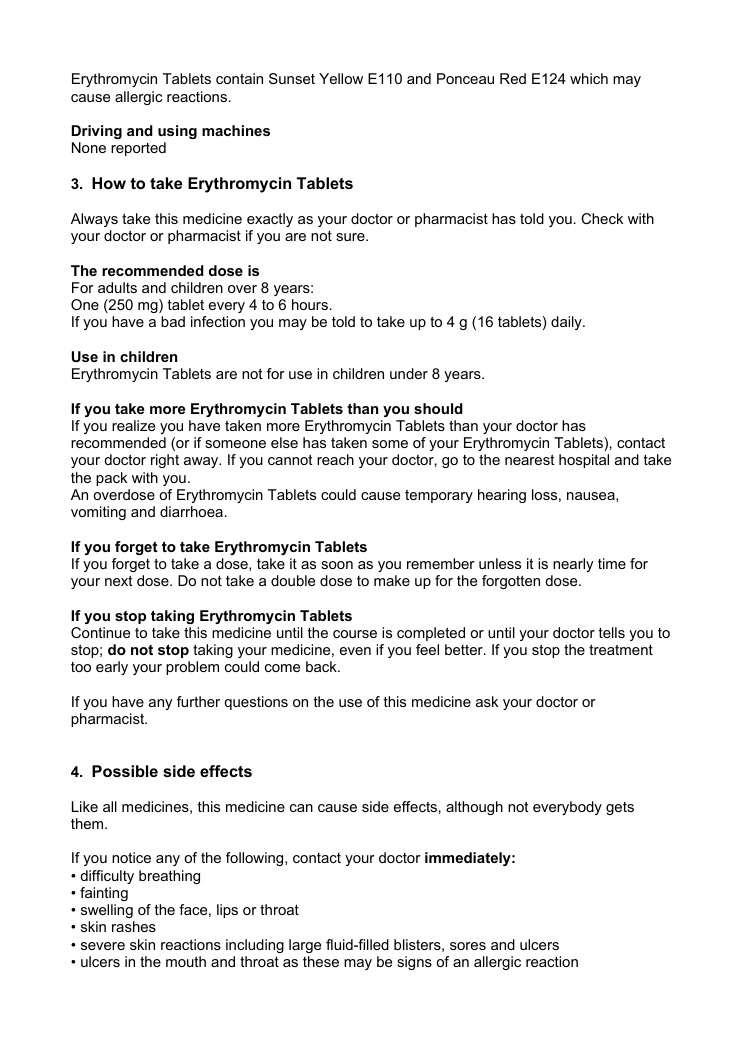

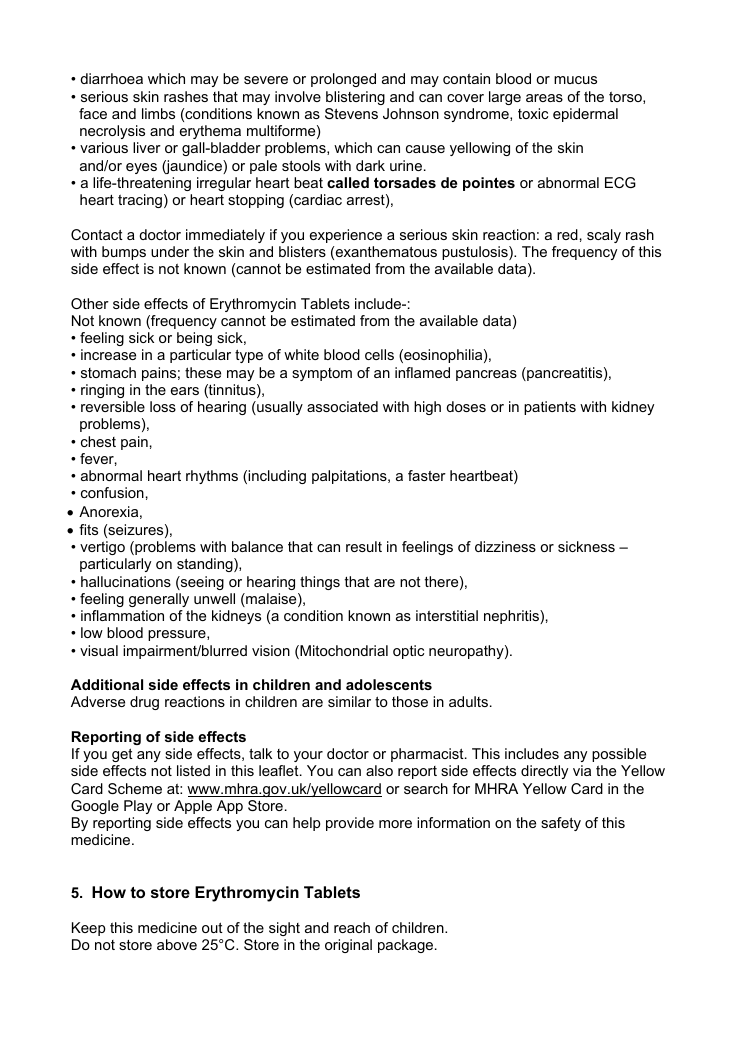

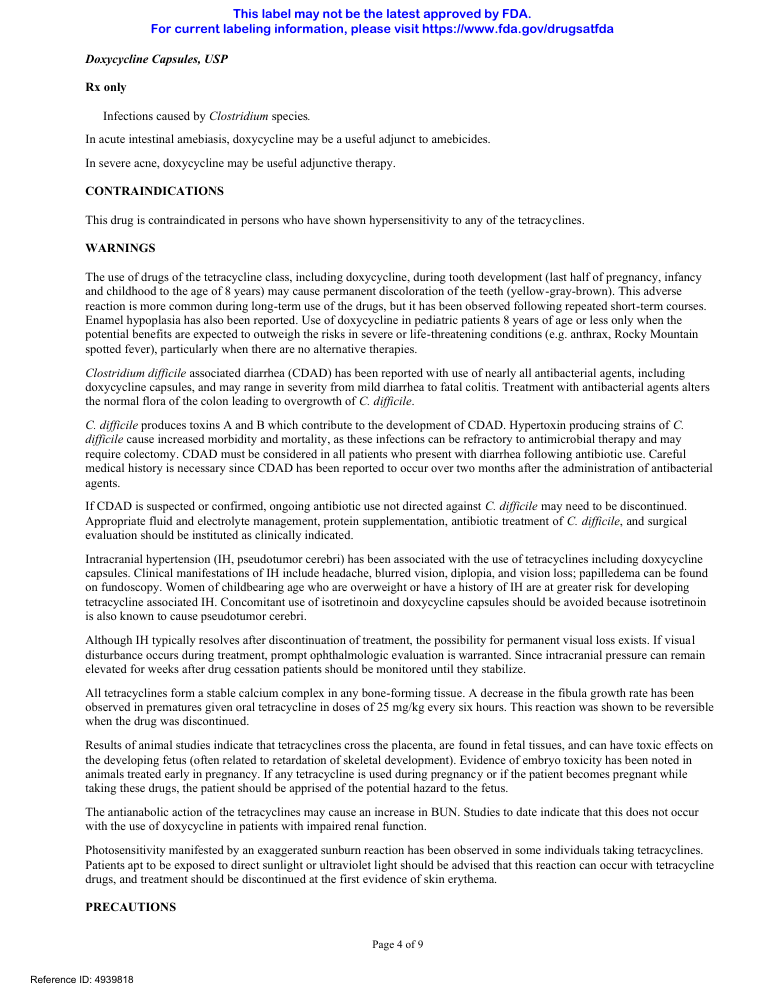

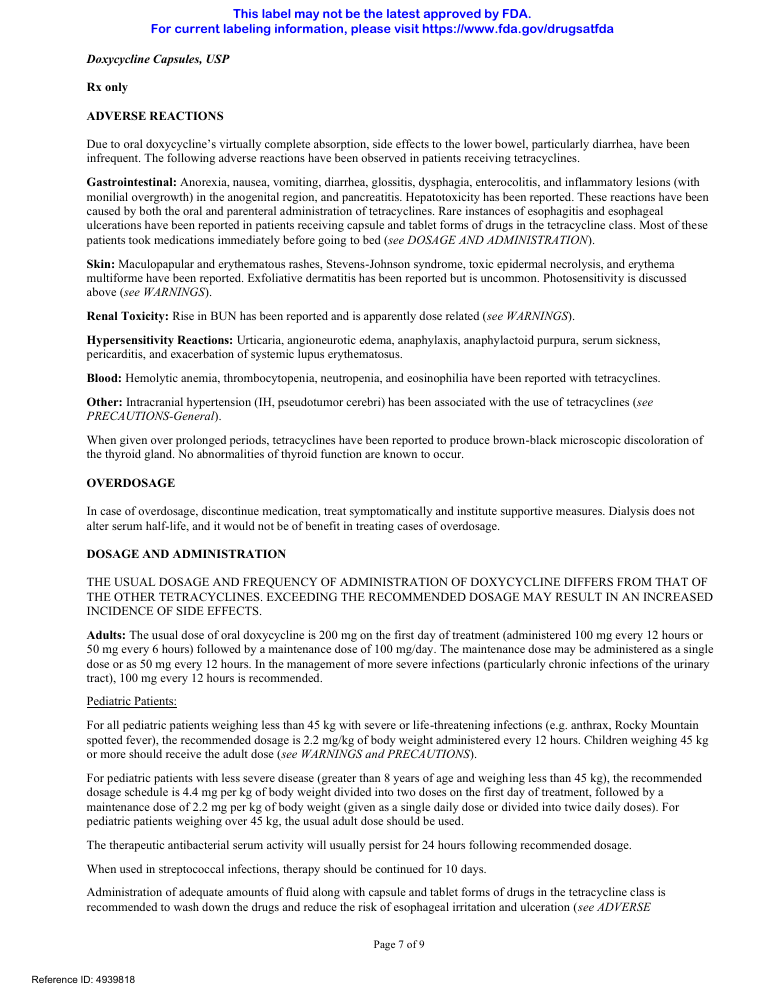

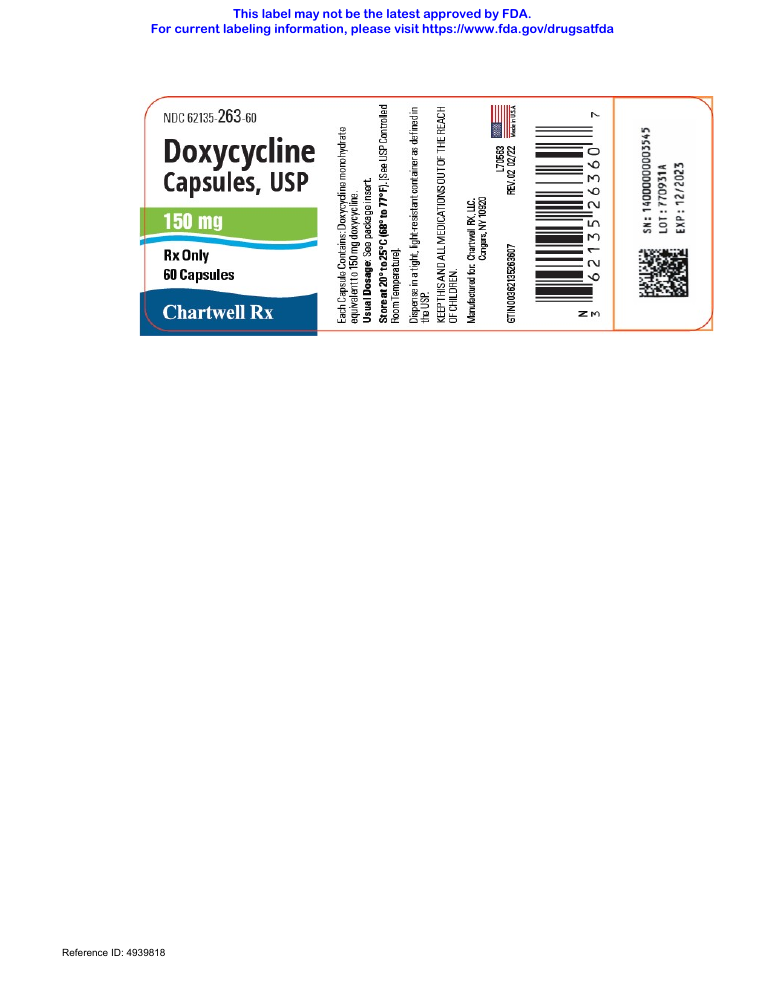

In [6]:

for rel in ['pages/erythromycin/page-4.png','pages/erythromycin/page-5.png','pages/doxycycline/page-04.png','pages/doxycycline/page-07.png','pages/doxycycline/page-10.png']:
    print(rel);display(Image(filename=str(F/rel)))


**Görsel yorumu:**Erythromycin'in kullanıcı istediği4–5'i ileDoxycycline'nin7'si veuyarı4'ü tam sayfa gösterilir. Ambalaj10'un görüntüsü metin katmanıyla aynı şey değildir;bu görseldeki yazılar OCR yapılmış alıntı diye JSON'a eklenmedi. OrijinalPDF'ler değiştirilmedi.

## 6. Testler,provenans vedurma noktası

In [7]:

print((Q/'pilot_tests_v1.txt').read_text(encoding='utf-8'))
display(pd.DataFrame([json.loads((Q/'evidence_complete.json').read_text(encoding='utf-8'))]).T)
from wp12_pilot import preserve
print('Hash ile değişmediği doğrulanan eski dosya/seçiliPDF:',preserve())


test_01_only_user_selected_sources_exist_and_hash_match (test_wp12_pilot.RealPDFPilotTests.test_01_only_user_selected_sources_exist_and_hash_match) ... ok
test_02_real_page_counts_and_pdf_format (test_wp12_pilot.RealPDFPilotTests.test_02_real_page_counts_and_pdf_format) ... ok
test_03_existing_contract_accepts_real_bundle (test_wp12_pilot.RealPDFPilotTests.test_03_existing_contract_accepts_real_bundle) ... ok
test_04_all_pages_reextract_exactly_offline_no_subprocess (test_wp12_pilot.RealPDFPilotTests.test_04_all_pages_reextract_exactly_offline_no_subprocess) ... ok
test_05_all_quote_spans_and_hashes_exact (test_wp12_pilot.RealPDFPilotTests.test_05_all_quote_spans_and_hashes_exact) ... ok
test_06_user_requested_pages_and_section_boundaries (test_wp12_pilot.RealPDFPilotTests.test_06_user_requested_pages_and_section_boundaries) ... ok
test_07_physical_vs_visible_printed_number (test_wp12_pilot.RealPDFPilotTests.test_07_physical_vs_visible_printed_number) ... ok
test_08_image_package_page_

,0
documents,2
physical_pages,17
source_quotes,44
context_annotations,44
training_labels_generated,0
model_inputs_generated,0
clinical_adjudication,False
LLM,False
OCR,False
old_files_preserved,3208


**Sonuç:**18 gerçek test geçti;tüm17 sayfa ağ/alt süreç erişimi engellenmiş tekrar çıkarımında aynı kaldı.44 quote'un aralık/hash/page bağlantısı geçerlidir.44 sayısı ADR sınıfı/olay sayısı değildir;üst/alt dilimler örtüşür. Eski şema,hazırlık kaydı,kohort,model/sonuç/QA dosyaları değişmedi. Yeni SIDER etiketi,model girdisi,eğitim veyaLLM çalışması yoktur. **Kaynak doğrulama pilotu burada durur;kullanıcı incelemesi beklenir.**